In [1]:

from pathlib import Path
from collections import Counter
import csv
import random
import numpy as np
import torch
import timm

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Project paths
DATA_DIR = Path.cwd()
SPLIT_FILE = DATA_DIR / "dataset_split.csv"

MODEL_NAME = "tiny_vit_11m_224.in1k"

RESULTS_DIR = DATA_DIR / "results" / "tinyvit_11m"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# 3. Apple GPU
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# 4. Verify dataset split
assert SPLIT_FILE.exists(), "dataset_split.csv not found"

with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

split_counts = Counter(
    row["split"] for row in split_records
)

assert split_counts == {
    "train": 1402,
    "validation": 280,
    "test": 279
}

# 5. Check available pretrained models
available_models = timm.list_models(
    "*tiny_vit_11m*",
    pretrained=True,
    include_tags=True
)

print("Available TinyViT-11M models:")
for name in available_models:
    print(" -", name)

assert MODEL_NAME in available_models

# 6. Load pretrained TinyViT
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=3
)

model = model.to(DEVICE)
model.eval()

# 7. Parameter counts
total_params = sum(
    p.numel() for p in model.parameters()
)

resnet18_params = 11_178_051

print("\nMODEL INFORMATION")
print("-" * 50)

print("Architecture:", MODEL_NAME)
print("Device:", DEVICE)
print("Total parameters:", f"{total_params:,}")
print("ResNet-18 parameters:", f"{resnet18_params:,}")

difference = (
    (total_params / resnet18_params) - 1
) * 100

print(f"Parameter difference: {difference:+.2f}%")

# 8. Classification head
print("\nCLASSIFICATION HEAD")
print(model.get_classifier())

# 9. Inspect pretrained preprocessing requirements
print("\nPRETRAINED DATA CONFIG")
data_config = timm.data.resolve_model_data_config(model)

for key in ["input_size", "mean", "std", "interpolation"]:
    print(f"{key}: {data_config.get(key)}")

# 10. Verify model forward pass
dummy_images = torch.randn(
    2, 3, 224, 224,
    device=DEVICE
)

with torch.inference_mode():
    outputs = model(dummy_images)

print("\nFORWARD PASS")
print("Input shape:", dummy_images.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (2, 3)

print("\nDATASET")
print(dict(split_counts))

print("\nResults directory:", RESULTS_DIR)
print("\nSetup successful!")


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Available TinyViT-11M models:
 - tiny_vit_11m_224.dist_in22k
 - tiny_vit_11m_224.dist_in22k_ft_in1k
 - tiny_vit_11m_224.in1k



MODEL INFORMATION
--------------------------------------------------
Architecture: tiny_vit_11m_224.in1k
Device: mps
Total parameters: 10,549,319
ResNet-18 parameters: 11,178,051
Parameter difference: -5.62%

CLASSIFICATION HEAD
Linear(in_features=448, out_features=3, bias=True)

PRETRAINED DATA CONFIG
input_size: (3, 224, 224)
mean: (0.485, 0.456, 0.406)
std: (0.229, 0.224, 0.225)
interpolation: bicubic

FORWARD PASS
Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 3])

DATASET
{'train': 1402, 'validation': 280, 'test': 279}

Results directory: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_11m

Setup successful!


In [2]:

import torch.nn as nn

# 1. Inspect the major architectural components
print("TINYVIT-11M ARCHITECTURE")
print("=" * 55)

for name, module in model.named_children():
    params = sum(
        p.numel() for p in module.parameters()
    )

    print(
        f"{name:20s} | "
        f"{type(module).__name__:25s} | "
        f"{params:,} parameters"
    )

# 2. Locate the classification head
classifier = model.get_classifier()

classifier_names = [
    name
    for name, module in model.named_modules()
    if module is classifier
]

assert len(classifier_names) == 1, (
    "Could not uniquely identify classification head"
)

print("\nCLASSIFICATION HEAD")
print("-" * 55)

print("Module name:", classifier_names[0])
print("Structure:", classifier)

# 3. Freeze all pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# 4. Unfreeze only the classification head
for param in classifier.parameters():
    param.requires_grad = True

# 5. Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print("\nHEAD-ONLY TRAINING CONFIGURATION")
print("-" * 55)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {frozen_params:,}")

print("\nTrainable layers:")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  {name}: {tuple(param.shape)}")

# 6. Preserve frozen BatchNorm statistics
model.eval()

# 7. Verify that only the classifier is trainable
classifier_params = sum(
    p.numel() for p in classifier.parameters()
)

assert trainable_params == classifier_params
assert trainable_params == (448 * 3 + 3)

print("\nArchitecture inspection complete!")


TINYVIT-11M ARCHITECTURE
patch_embed          | PatchEmbed                | 19,488 parameters
stages               | Sequential                | 10,527,588 parameters
head                 | NormMlpClassifierHead     | 2,243 parameters

CLASSIFICATION HEAD
-------------------------------------------------------
Module name: head.fc
Structure: Linear(in_features=448, out_features=3, bias=True)

HEAD-ONLY TRAINING CONFIGURATION
-------------------------------------------------------
Total parameters:     10,549,319
Trainable parameters: 1,347
Frozen parameters:    10,547,972

Trainable layers:
  head.fc.weight: (3, 448)
  head.fc.bias: (3,)

Architecture inspection complete!


In [3]:

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# 1. Identical class mapping
CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

# 2. Reuse existing dataset split
train_records = [
    row for row in split_records
    if row["split"] == "train"
]

val_records = [
    row for row in split_records
    if row["split"] == "validation"
]

test_records = [
    row for row in split_records
    if row["split"] == "test"
]

# 3. Identical preprocessing
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 4. SEM image dataset
class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]

        image_path = (
            self.data_dir / row["label"] / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        label = class_to_idx[row["label"]]

        return image, label

# 5. Create datasets
train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)

val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)

test_dataset = SEMDataset(
    test_records, DATA_DIR, eval_transform
)

# 6. Create DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Keep test data reserved for final evaluation.
# No test DataLoader needed yet.

# 7. Verify dataset
train_counts = Counter(
    row["label"] for row in train_records
)

assert len(train_dataset) == 1402
assert len(val_dataset) == 280
assert len(test_dataset) == 279

images, labels = next(iter(train_loader))

assert images.shape == (BATCH_SIZE, 3, 224, 224)

print("TINYVIT DATASET VERIFICATION")
print("-" * 45)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Reserved test images:", len(test_dataset))

print("\nClass distribution:")
for cls in CLASSES:
    print(f"  {cls}: {train_counts[cls]}")

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nImage batch:", images.shape)
print("Label batch:", labels.shape)

print("\nDataset setup successful!")


TINYVIT DATASET VERIFICATION
---------------------------------------------
Training images: 1402
Validation images: 280
Reserved test images: 279

Class distribution:
  Brittle: 589
  Ductile: 711
  Mixed: 102

Training batches: 88
Validation batches: 18

Image batch: torch.Size([16, 3, 224, 224])
Label batch: torch.Size([16])

Dataset setup successful!


In [4]:

import torch.nn as nn

# 1. Calculate class weights using training images only
num_samples = len(train_records)
num_classes = len(CLASSES)

class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[cls])
        for cls in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

# 2. Weighted cross-entropy
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 3. Optimizer — classification layer only
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

optimizer = torch.optim.AdamW(
    model.head.fc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# 4. Keep pretrained backbone in evaluation mode
model.eval()

# 5. Verify trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

optimized_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

assert trainable_params == 1347
assert optimized_params == trainable_params

# 6. Print configuration
print("TINYVIT-11M TRAINING CONFIGURATION")
print("=" * 55)

print("\nCLASS WEIGHTS")
for cls, weight in zip(CLASSES, class_weights):
    print(f"{cls}: {weight.item():.4f}")

print("\nMODEL PARAMETERS")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {total_params - trainable_params:,}")

print("\nOPTIMIZER")
print("Type:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Loss:", criterion)

print("\nConfiguration verified!")


TINYVIT-11M TRAINING CONFIGURATION

CLASS WEIGHTS
Brittle: 0.7934
Ductile: 0.6573
Mixed: 4.5817

MODEL PARAMETERS
Total parameters:     10,549,319
Trainable parameters: 1,347
Frozen parameters:    10,547,972

OPTIMIZER
Type: AdamW
Learning rate: 0.001
Weight decay: 0.0001
Loss: CrossEntropyLoss()

Configuration verified!


In [5]:

import time
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# 1. Training configuration
NUM_EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_precision": [],
    "val_mixed_recall": [],
    "val_mixed_f1": [],
    "epoch_time": []
}

best_f1 = -1.0
best_epoch = 0

checkpoint_path = (
    CHECKPOINT_DIR / "tinyvit_11m_best.pth"
)

print("TRAINING TINYVIT-11M")
print("=" * 75)

# 2. Training loop
for epoch in range(NUM_EPOCHS):

    if DEVICE.type == "mps":
        torch.mps.synchronize()

    start_time = time.perf_counter()

    # Keep the pretrained backbone and normalization
    # layers in evaluation mode.
    # Gradients still update head.fc.
    model.eval()

    train_loss_total = 0.0
    train_samples = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        # Weighted classification loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update classification layer only
        optimizer.step()

        train_loss_total += (
            loss.item() * labels.size(0)
        )
        train_samples += labels.size(0)

    train_loss = train_loss_total / train_samples

    # 3. Validation
    model.eval()

    val_loss_total = 0.0
    val_samples = 0

    all_labels = []
    all_predictions = []

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += (
                loss.item() * labels.size(0)
            )
            val_samples += labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(
                labels.cpu().tolist()
            )
            all_predictions.extend(
                predictions.cpu().tolist()
            )

    val_loss = val_loss_total / val_samples

    # 4. Calculate validation metrics
    val_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_precision = precision_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    val_mixed_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    # 5. Record epoch time
    if DEVICE.type == "mps":
        torch.mps.synchronize()

    elapsed = time.perf_counter() - start_time

    # 6. Save training history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)
    history["val_mixed_precision"].append(
        val_mixed_precision
    )
    history["val_mixed_recall"].append(
        val_mixed_recall
    )
    history["val_mixed_f1"].append(val_mixed_f1)
    history["epoch_time"].append(elapsed)

    # 7. Save best checkpoint by validation Macro-F1
    if val_macro_f1 > best_f1:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save({
            "model_state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },
            "epoch": best_epoch,
            "val_macro_f1": best_f1,
            "val_accuracy": val_accuracy,
            "val_mixed_f1": val_mixed_f1,
            "class_to_idx": class_to_idx,
            "model_name": MODEL_NAME,
            "experiment": "head_only"
        }, checkpoint_path)

        status = "NEW BEST"
    else:
        status = ""

    # 8. Print epoch results
    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.3f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed F1: {val_mixed_f1:.3f} | "
        f"Mixed Recall: {val_mixed_recall:.3f} | "
        f"Time: {elapsed:.1f}s | "
        f"{status}"
    )

# 9. Restore best checkpoint
best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# 10. Final summary
print("\nTRAINING COMPLETED")
print("=" * 55)

print("Best epoch:", best_epoch)
print(f"Best validation Macro-F1: {best_f1:.4f}")
print(
    "Mixed F1 at best epoch:",
    f"{best_checkpoint['val_mixed_f1']:.4f}"
)

print("\nREFERENCE COMPARISON")
print("ResNet-18 head-only:    0.9434")
print("ResNet-18 fine-tuned:   0.9525")
print("DeiT-Tiny fine-tuned:   0.8954")
print(f"TinyViT-11M head-only:  {best_f1:.4f}")

print(
    "\nAverage epoch time:",
    f"{np.mean(history['epoch_time']):.1f}s"
)

print("\nCheckpoint saved:", checkpoint_path)


TRAINING TINYVIT-11M
Epoch 01/10 | Train Loss: 0.5068 | Val Loss: 0.1896 | Accuracy: 0.954 | Macro-F1: 0.9084 | Mixed F1: 0.784 | Mixed Recall: 0.952 | Time: 9.6s | NEW BEST
Epoch 02/10 | Train Loss: 0.2733 | Val Loss: 0.1852 | Accuracy: 0.950 | Macro-F1: 0.8952 | Mixed F1: 0.741 | Mixed Recall: 0.952 | Time: 9.0s | 
Epoch 03/10 | Train Loss: 0.2261 | Val Loss: 0.1326 | Accuracy: 0.961 | Macro-F1: 0.9137 | Mixed F1: 0.784 | Mixed Recall: 0.952 | Time: 9.0s | NEW BEST
Epoch 04/10 | Train Loss: 0.2002 | Val Loss: 0.1689 | Accuracy: 0.946 | Macro-F1: 0.8892 | Mixed F1: 0.727 | Mixed Recall: 0.952 | Time: 9.0s | 
Epoch 05/10 | Train Loss: 0.1904 | Val Loss: 0.1080 | Accuracy: 0.971 | Macro-F1: 0.9344 | Mixed F1: 0.833 | Mixed Recall: 0.952 | Time: 8.7s | NEW BEST
Epoch 06/10 | Train Loss: 0.1733 | Val Loss: 0.1036 | Accuracy: 0.968 | Macro-F1: 0.9245 | Mixed F1: 0.809 | Mixed Recall: 0.905 | Time: 8.5s | 
Epoch 07/10 | Train Loss: 0.1606 | Val Loss: 0.0898 | Accuracy: 0.975 | Macro-F1: 0.9

TINYVIT-11M — HEAD-ONLY CLASSIFICATION
Best epoch: 9
Accuracy: 0.9750
Macro-F1: 0.9396

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Brittle     1.0000    0.9915    0.9957       117
     Ductile     0.9857    0.9718    0.9787       142
       Mixed     0.7917    0.9048    0.8444        21

    accuracy                         0.9750       280
   macro avg     0.9258    0.9560    0.9396       280
weighted avg     0.9771    0.9750    0.9757       280



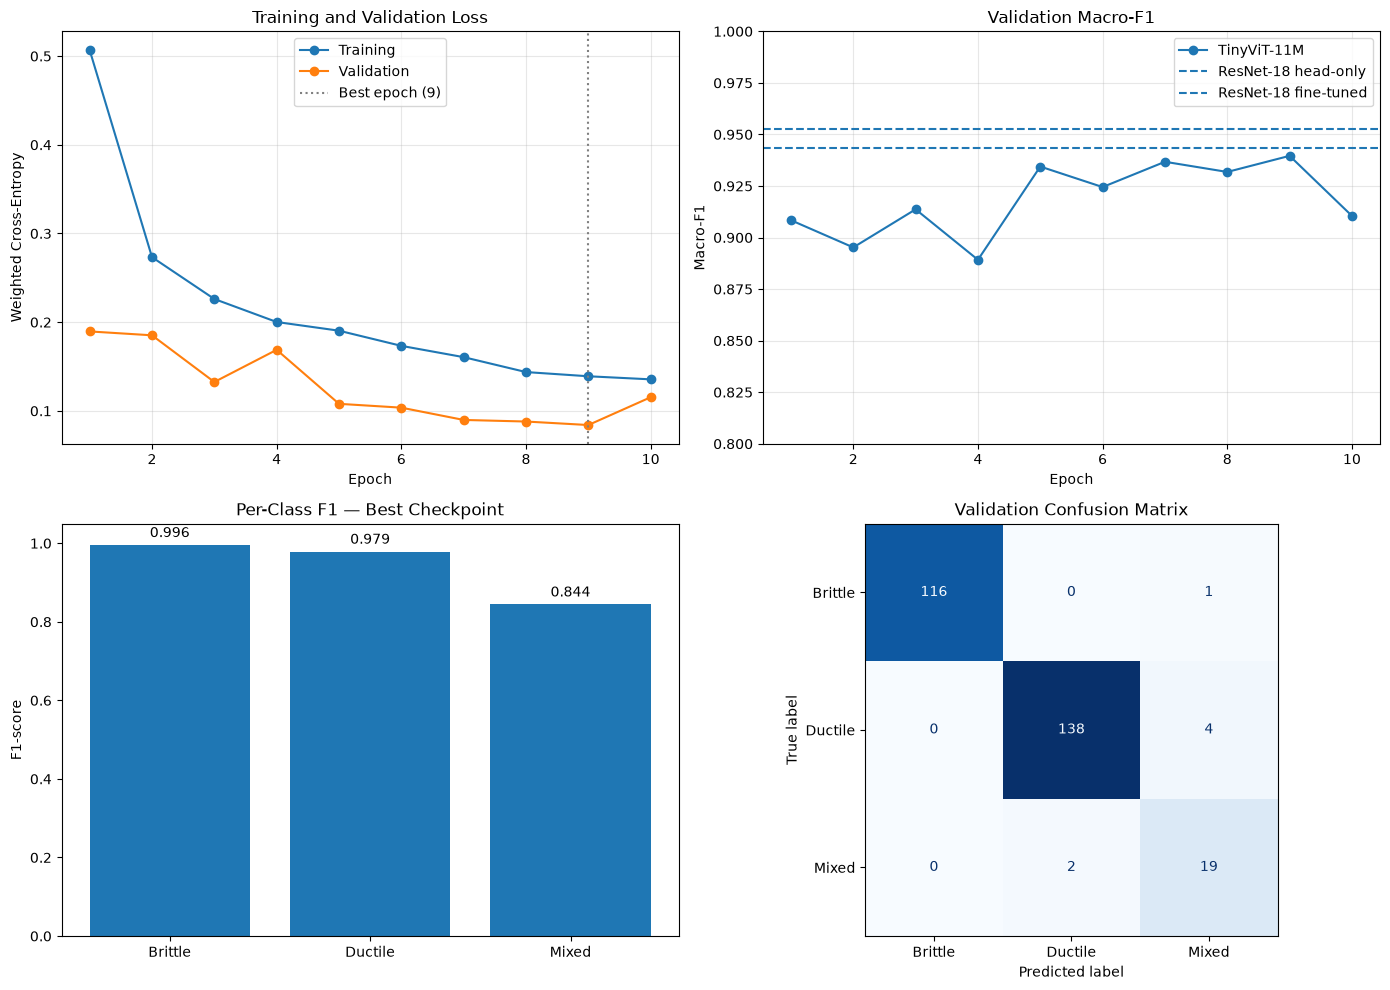


MISCLASSIFIED VALIDATION IMAGES
-----------------------------------------------------------------
100Cr6_AR_06_10.png | Actual: Brittle | Predicted: Mixed
304_H2_04_25.png | Actual: Ductile | Predicted: Mixed
316L_AR_04_7.png | Actual: Ductile | Predicted: Mixed
316L_AR_21_20.png | Actual: Ductile | Predicted: Mixed
316L_AR_23_13.png | Actual: Ductile | Predicted: Mixed
316L_AR_04_15.png | Actual: Mixed | Predicted: Ductile
mX65_H2_26_29.png | Actual: Mixed | Predicted: Ductile

Total errors: 7
Diagnostic plot saved: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_11m/plots/tinyvit_head_only_diagnostics.png


In [6]:

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Evaluate the best saved TinyViT checkpoint
model.eval()

y_true = []
y_pred = []

with torch.inference_mode():
    for images, labels in val_loader:
        outputs = model(images.to(DEVICE))
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

# Verify that predictions align with the saved split
assert len(y_true) == len(val_records)

assert all(
    CLASSES[y_true[i]] == val_records[i]["label"]
    for i in range(len(y_true))
)

# 2. Print classification report
print("TINYVIT-11M — HEAD-ONLY CLASSIFICATION")
print("=" * 60)

print("Best epoch:", best_epoch)
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro-F1: {f1_score(y_true, y_pred, average='macro'):.4f}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

# 3. Compute class-level F1 and confusion matrix
class_f1 = f1_score(
    y_true, y_pred,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

cm = confusion_matrix(
    y_true, y_pred,
    labels=[0, 1, 2]
)

# 4. Create four diagnostic plots
epochs = np.arange(
    1, len(history["train_loss"]) + 1
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

# Plot A — Training and validation loss
axes[0, 0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training"
)

axes[0, 0].plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation"
)

axes[0, 0].axvline(
    best_epoch,
    linestyle=":",
    color="gray",
    label=f"Best epoch ({best_epoch})"
)

axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Weighted Cross-Entropy")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Plot B — Macro-F1 comparison
axes[0, 1].plot(
    epochs,
    history["val_macro_f1"],
    marker="o",
    label="TinyViT-11M"
)

axes[0, 1].axhline(
    0.9434,
    linestyle="--",
    label="ResNet-18 head-only"
)

axes[0, 1].axhline(
    0.9525,
    linestyle="--",
    label="ResNet-18 fine-tuned"
)

axes[0, 1].set_title("Validation Macro-F1")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Macro-F1")
axes[0, 1].set_ylim(0.80, 1.0)
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Plot C — Per-class F1
bars = axes[1, 0].bar(
    CLASSES,
    class_f1
)

axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].set_title("Per-Class F1 — Best Checkpoint")
axes[1, 0].set_ylabel("F1-score")

for bar, value in zip(bars, class_f1):
    axes[1, 0].text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

# Plot D — Confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
).plot(
    ax=axes[1, 1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[1, 1].set_title("Validation Confusion Matrix")

plt.tight_layout()

plot_path = (
    PLOTS_DIR / "tinyvit_head_only_diagnostics.png"
)

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 5. List incorrect predictions
error_indices = [
    i for i, (actual, predicted) in enumerate(
        zip(y_true, y_pred)
    )
    if actual != predicted
]

print("\nMISCLASSIFIED VALIDATION IMAGES")
print("-" * 65)

for i in error_indices:
    row = val_records[i]

    print(
        f"{row['filename']} | "
        f"Actual: {CLASSES[y_true[i]]} | "
        f"Predicted: {CLASSES[y_pred[i]]}"
    )

print(f"\nTotal errors: {len(error_indices)}")
print("Diagnostic plot saved:", plot_path)
